# Supervised Learning: Data Preparation

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_style("whitegrid")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True)

SEED = 42

## 1. Load the Labeled Sample

In [2]:
X = pd.read_csv("cluster_sample_unlabeled.csv")
y = pd.read_csv("cluster_sample_labels.csv")["Label"]

df = X.copy()
df["Label"] = y

print(f"Labeled sample: {df.shape[0]:,} rows, {X.shape[1]} features, 1 label column")
print(f"Traffic types:  {y.nunique()}")
print(f"Missing values: {int(df.isna().sum().sum())}")

Labeled sample: 11,720 rows, 65 features, 1 label column
Traffic types:  15
Missing values: 0


## 2. Remove Duplicate Rows

In [3]:
dup_mask = df.duplicated(keep="first")
print(f"Duplicate rows: {int(dup_mask.sum()):,}")
print()
print(df.loc[dup_mask, "Label"].value_counts().to_string())

# Check that no identical feature vector carries two different labels
conflicts = (df.groupby(list(X.columns))["Label"].nunique() > 1).sum()
print(f"\nFeature vectors with conflicting labels: {int(conflicts)}")

df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows after removing duplicates: {len(df):,}")

Duplicate rows: 994

Label
PortScan    771
Bot         222
BENIGN        1

Feature vectors with conflicting labels: 0
Rows after removing duplicates: 10,726


In [ ]:
counts = df["Label"].value_counts()
counts.to_frame("flows")

## 3. Split into Training and Testing Sets

The data is split 70% / 30% at random with a fixed seed.

In [4]:
features = df.drop(columns="Label")
labels = df["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.30, stratify=labels, random_state=SEED
)

train = X_train.copy(); train["Label"] = y_train
test = X_test.copy();   test["Label"] = y_test

print(f"Training set: {len(train):,} rows ({len(train)/len(df):.0%})")
print(f"Testing set:  {len(test):,} rows ({len(test)/len(df):.0%})")

Training set: 7,508 rows (70%)
Testing set:  3,218 rows (30%)


## 4. Verify the Sets Are Disjoint

In [5]:
shared_index = set(train.index) & set(test.index)

train_hash = set(pd.util.hash_pandas_object(train.drop(columns="Label"), index=False))
test_hash = set(pd.util.hash_pandas_object(test.drop(columns="Label"), index=False))
shared_rows = train_hash & test_hash

print(f"Row positions in both sets:     {len(shared_index)}")
print(f"Identical feature rows in both: {len(shared_rows)}")
assert len(shared_index) == 0 and len(shared_rows) == 0
print("Training and testing sets are disjoint.")

Row positions in both sets:     0
Identical feature rows in both: 0
Training and testing sets are disjoint.


## 5. Save the Files

In [6]:
df.to_csv("supervised_sample_labeled.csv", index=False)
train.to_csv("train_set.csv", index=False)
test.to_csv("test_set.csv", index=False)

for name in ["supervised_sample_labeled.csv", "train_set.csv", "test_set.csv"]:
    print(f"{name:32s} {os.path.getsize(name)/1e6:5.1f} MB")

supervised_sample_labeled.csv      3.8 MB
train_set.csv                      2.6 MB
test_set.csv                       1.1 MB


## 6. Figures

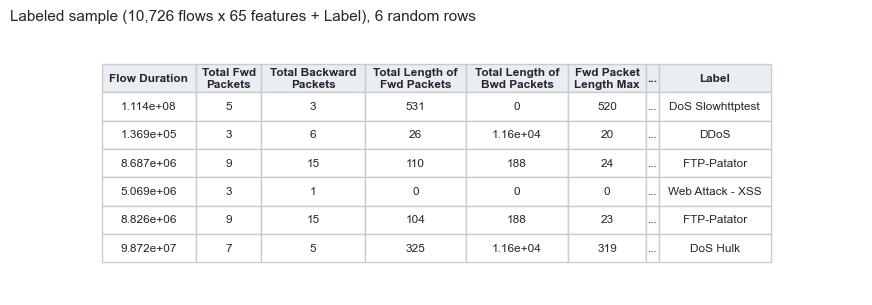

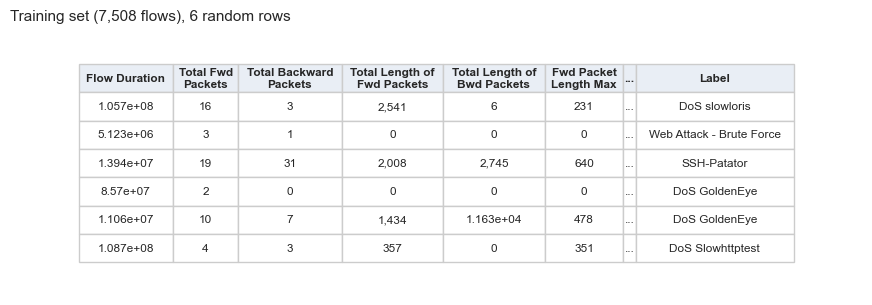

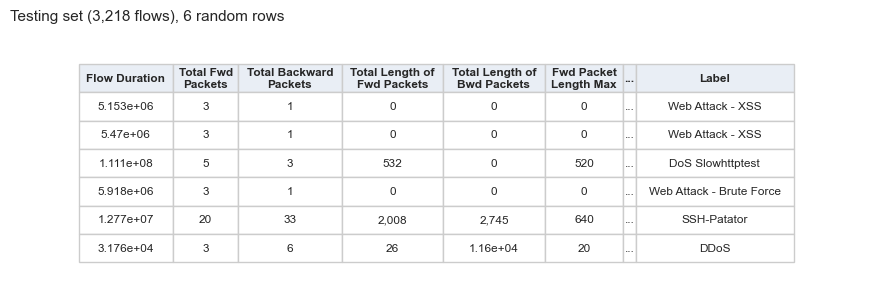

In [7]:
import textwrap

def table_image(data, path, title, n_rows=6, n_feat=6):
    sub = data.sample(n_rows, random_state=SEED)
    cols = list(data.columns[:n_feat])
    body = sub[cols].map(lambda v: f"{v:,.4g}").copy()
    body.insert(n_feat, "...", "...")
    body["Label"] = sub["Label"].values
    header = [textwrap.fill(c, 16) for c in body.columns]

    fig, ax = plt.subplots(figsize=(11, 0.9 + 0.42 * n_rows))
    ax.axis("off")
    ax.set_title(title, fontsize=11, loc="left", pad=8)
    tbl = ax.table(cellText=body.values, colLabels=header, loc="center", cellLoc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(8.5)
    tbl.scale(1, 1.7)
    tbl.auto_set_column_width(list(range(len(body.columns))))
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor("#cccccc")
        if r == 0:
            cell.set_facecolor("#e9eef5")
            cell.set_text_props(weight="bold")
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()

table_image(df, "figures/supervised-01-labeled-sample.png",
            f"Labeled sample ({len(df):,} flows x 65 features + Label), 6 random rows")
table_image(train, "figures/supervised-02-train-set.png",
            f"Training set ({len(train):,} flows), 6 random rows")
table_image(test, "figures/supervised-03-test-set.png",
            f"Testing set ({len(test):,} flows), 6 random rows")

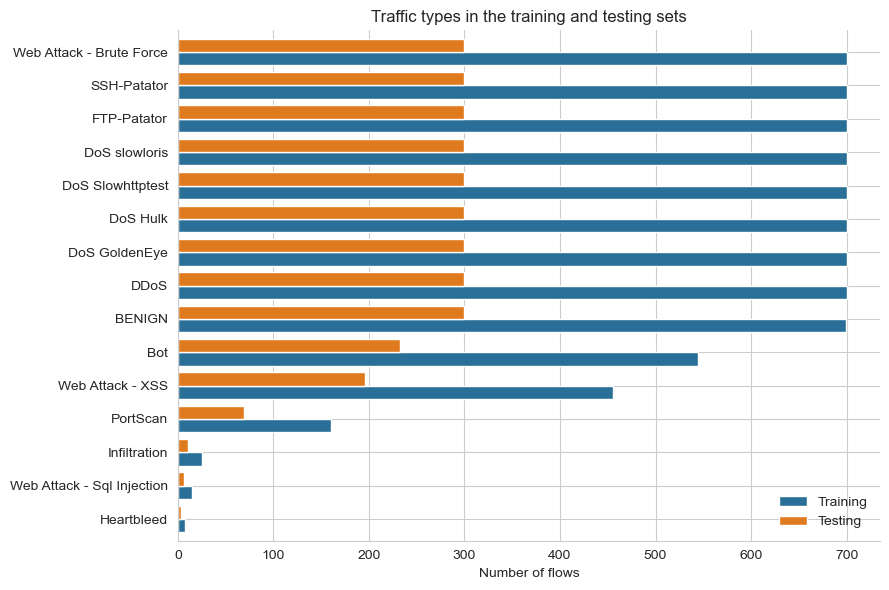

,Training,Testing,test_share
Label,,,
Heartbleed,8,3,0.273
Web Attack - Sql Injection,15,6,0.286
Infiltration,25,11,0.306
PortScan,160,69,0.301
Web Attack - XSS,456,196,0.301
Bot,545,233,0.299
BENIGN,699,300,0.300
DDoS,700,300,0.300
DoS GoldenEye,700,300,0.300


In [8]:
dist = pd.DataFrame({"Training": y_train.value_counts(), "Testing": y_test.value_counts()})
dist = dist.loc[dist.sum(axis=1).sort_values().index]

ax = dist.plot(kind="barh", figsize=(9, 6), color=["#2a6f97", "#e07a1f"], width=0.8)
ax.set_xlabel("Number of flows")
ax.set_ylabel("")
ax.set_title("Traffic types in the training and testing sets")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("figures/supervised-04-class-distribution.png", dpi=160, bbox_inches="tight")
plt.show()

dist.assign(test_share=(dist["Testing"] / dist.sum(axis=1)).round(3))